In [2]:
!pip install -q transformers datasets evaluate accelerate scikit-learn matplotlib seaborn huggingface_hub

import os
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from huggingface_hub import notebook_login, HfApi

# Verifique se a GPU T4 está ativa
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo em uso: {device.upper()}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Cole seu token de escrita (Write) do Hugging Face quando solicitado
notebook_login()

Dispositivo em uso: CUDA
GPU: Tesla T4


In [4]:
import pandas as pd
from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split

# 1. Carrega dataset público oficial de reviews reais em PT-BR diretamente via CSV
url = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv"
df = pd.read_csv(url, low_memory=False)

# 2. Seleciona texto e nota, removendo nulos e textos muito curtos
df = df[["review_text", "overall_rating"]].dropna()
df["review_text"] = df["review_text"].astype(str).str.strip()
df = df[df["review_text"].str.len() >= 15]

# 3. Mapeia notas (1-2: Negativo | 3: Neutro | 4-5: Positivo)
def map_sentiment(rating):
    if rating in [1, 2]:
        return 0  # Negativo
    elif rating == 3:
        return 1  # Neutro
    else:
        return 2  # Positivo

df["label"] = df["overall_rating"].apply(map_sentiment)

# 4. Amostragem balanceada (2.500 por classe = 7.500 amostras totais)
SAMPLES_PER_CLASS = 2500
df_balanced = (
    df.groupby("label", group_keys=False)
    .apply(lambda x: x.sample(n=min(len(x), SAMPLES_PER_CLASS), random_state=42))
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("Distribuição balanceada das classes:")
print(df_balanced["label"].value_counts())

# 5. Divisão estratificada: 80% Treino, 10% Validação, 10% Teste
train_df, temp_df = train_test_split(
    df_balanced[["review_text", "label"]],
    test_size=0.2,
    stratify=df_balanced["label"],
    random_state=42
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label"],
    random_state=42
)

dataset_dict = DatasetDict({
    "train": Dataset.from_pandas(train_df.reset_index(drop=True)),
    "validation": Dataset.from_pandas(val_df.reset_index(drop=True)),
    "test": Dataset.from_pandas(test_df.reset_index(drop=True)),
})

print(dataset_dict)

Distribuição balanceada das classes:
label
0    2500
2    2500
1    2500
Name: count, dtype: int64
DatasetDict({
    train: Dataset({
        features: ['review_text', 'label'],
        num_rows: 6000
    })
    validation: Dataset({
        features: ['review_text', 'label'],
        num_rows: 750
    })
    test: Dataset({
        features: ['review_text', 'label'],
        num_rows: 750
    })
})


/tmp/ipykernel_918/3816021800.py:29: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(len(x), SAMPLES_PER_CLASS), random_state=42))


In [5]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

MODEL_CHECKPOINT = "neuralmind/bert-base-portuguese-cased"
HF_REPO_ID = "GetulioCO/bertimbau-ptbr-review-classifier"  # <-- Ajuste se seu username no HF for outro

id2label = {0: "Negativo", 1: "Neutro", 2: "Positivo"}
label2id = {"Negativo": 0, "Neutro": 1, "Positivo": 2}

tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(examples):
    return tokenizer(
        examples["review_text"],
        padding="max_length",
        truncation=True,
        max_length=160
    )

tokenized_datasets = dataset_dict.map(tokenize_function, batched=True)

# Carrega modelo base sem fine-tuning para medir o Baseline
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
).to(device)

def evaluate_predictions(model, test_dataset):
    model.eval()
    preds = []
    labels = test_dataset["label"]
    batch_size = 32

    for i in range(0, len(test_dataset), batch_size):
        batch = test_dataset[i:i+batch_size]
        inputs = {
            "input_ids": torch.tensor(batch["input_ids"]).to(device),
            "attention_mask": torch.tensor(batch["attention_mask"]).to(device)
        }
        with torch.no_grad():
            outputs = model(**inputs)
            batch_preds = torch.argmax(outputs.logits, dim=-1).cpu().numpy()
            preds.extend(batch_preds)

    acc = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average="macro")
    f1_weighted = f1_score(labels, preds, average="weighted")
    return preds, acc, f1_macro, f1_weighted

_, base_acc, base_f1_macro, base_f1_weighted = evaluate_predictions(base_model, tokenized_datasets["test"])
print(f"--- BASELINE (SEM FINE-TUNING) ---")
print(f"Accuracy: {base_acc:.4f} | F1-Macro: {base_f1_macro:.4f} | F1-Weighted: {base_f1_weighted:.4f}")

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

--- BASELINE (SEM FINE-TUNING) ---
Accuracy: 0.3747 | F1-Macro: 0.2895 | F1-Weighted: 0.2895


In [6]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro"),
        "f1_weighted": f1_score(labels, predictions, average="weighted")
    }

training_args = TrainingArguments(
    output_dir="./results_bertimbau",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=torch.cuda.is_available(),  # Acelera treino em 2x na GPU T4
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    logging_steps=50,
    report_to="none"
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=base_model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.608951,0.541949,0.782667,0.773253,0.773253
2,0.494232,0.516675,0.786667,0.788835,0.788835
3,0.383454,0.523891,0.788000,0.787165,0.787165


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=564, training_loss=0.5273901528500496, metrics={'train_runtime': 188.6349, 'train_samples_per_second': 95.422, 'train_steps_per_second': 2.99, 'total_flos': 1480012974720000.0, 'train_loss': 0.5273901528500496, 'epoch': 3.0})


--- RESULTADOS PÓS FINE-TUNING (TEST SET) ---
              precision    recall  f1-score   support

    Negativo     0.8729    0.8240    0.8477       250
      Neutro     0.6441    0.7240    0.6817       250
    Positivo     0.7940    0.7400    0.7660       250

    accuracy                         0.7627       750
   macro avg     0.7703    0.7627    0.7652       750
weighted avg     0.7703    0.7627    0.7652       750



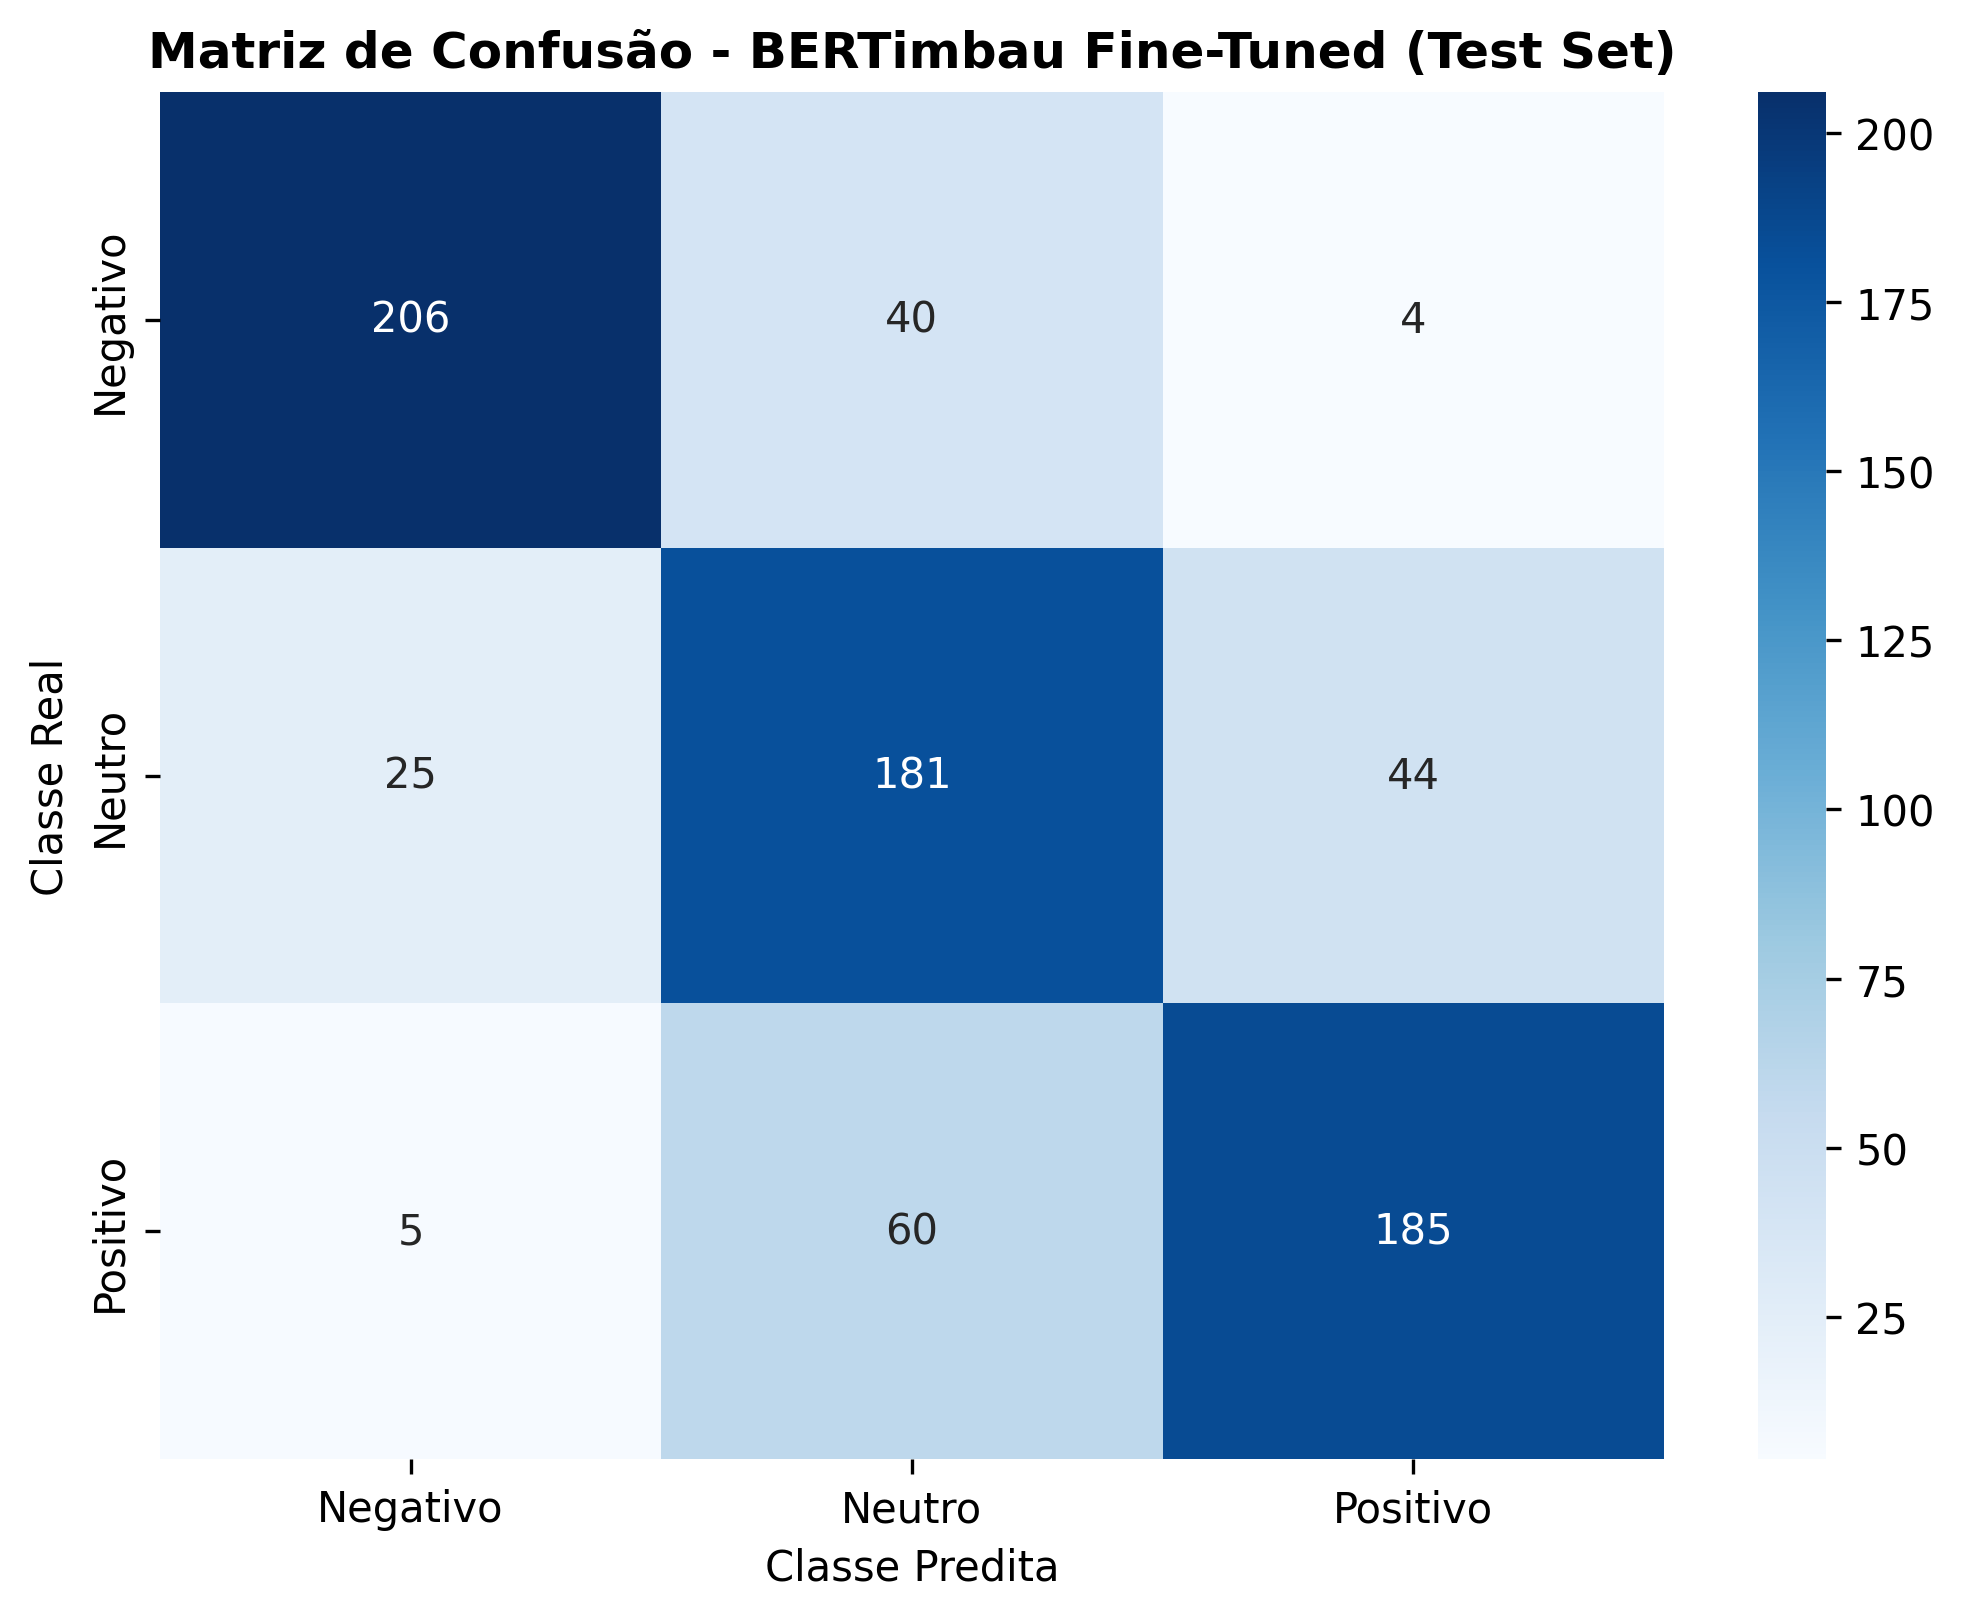

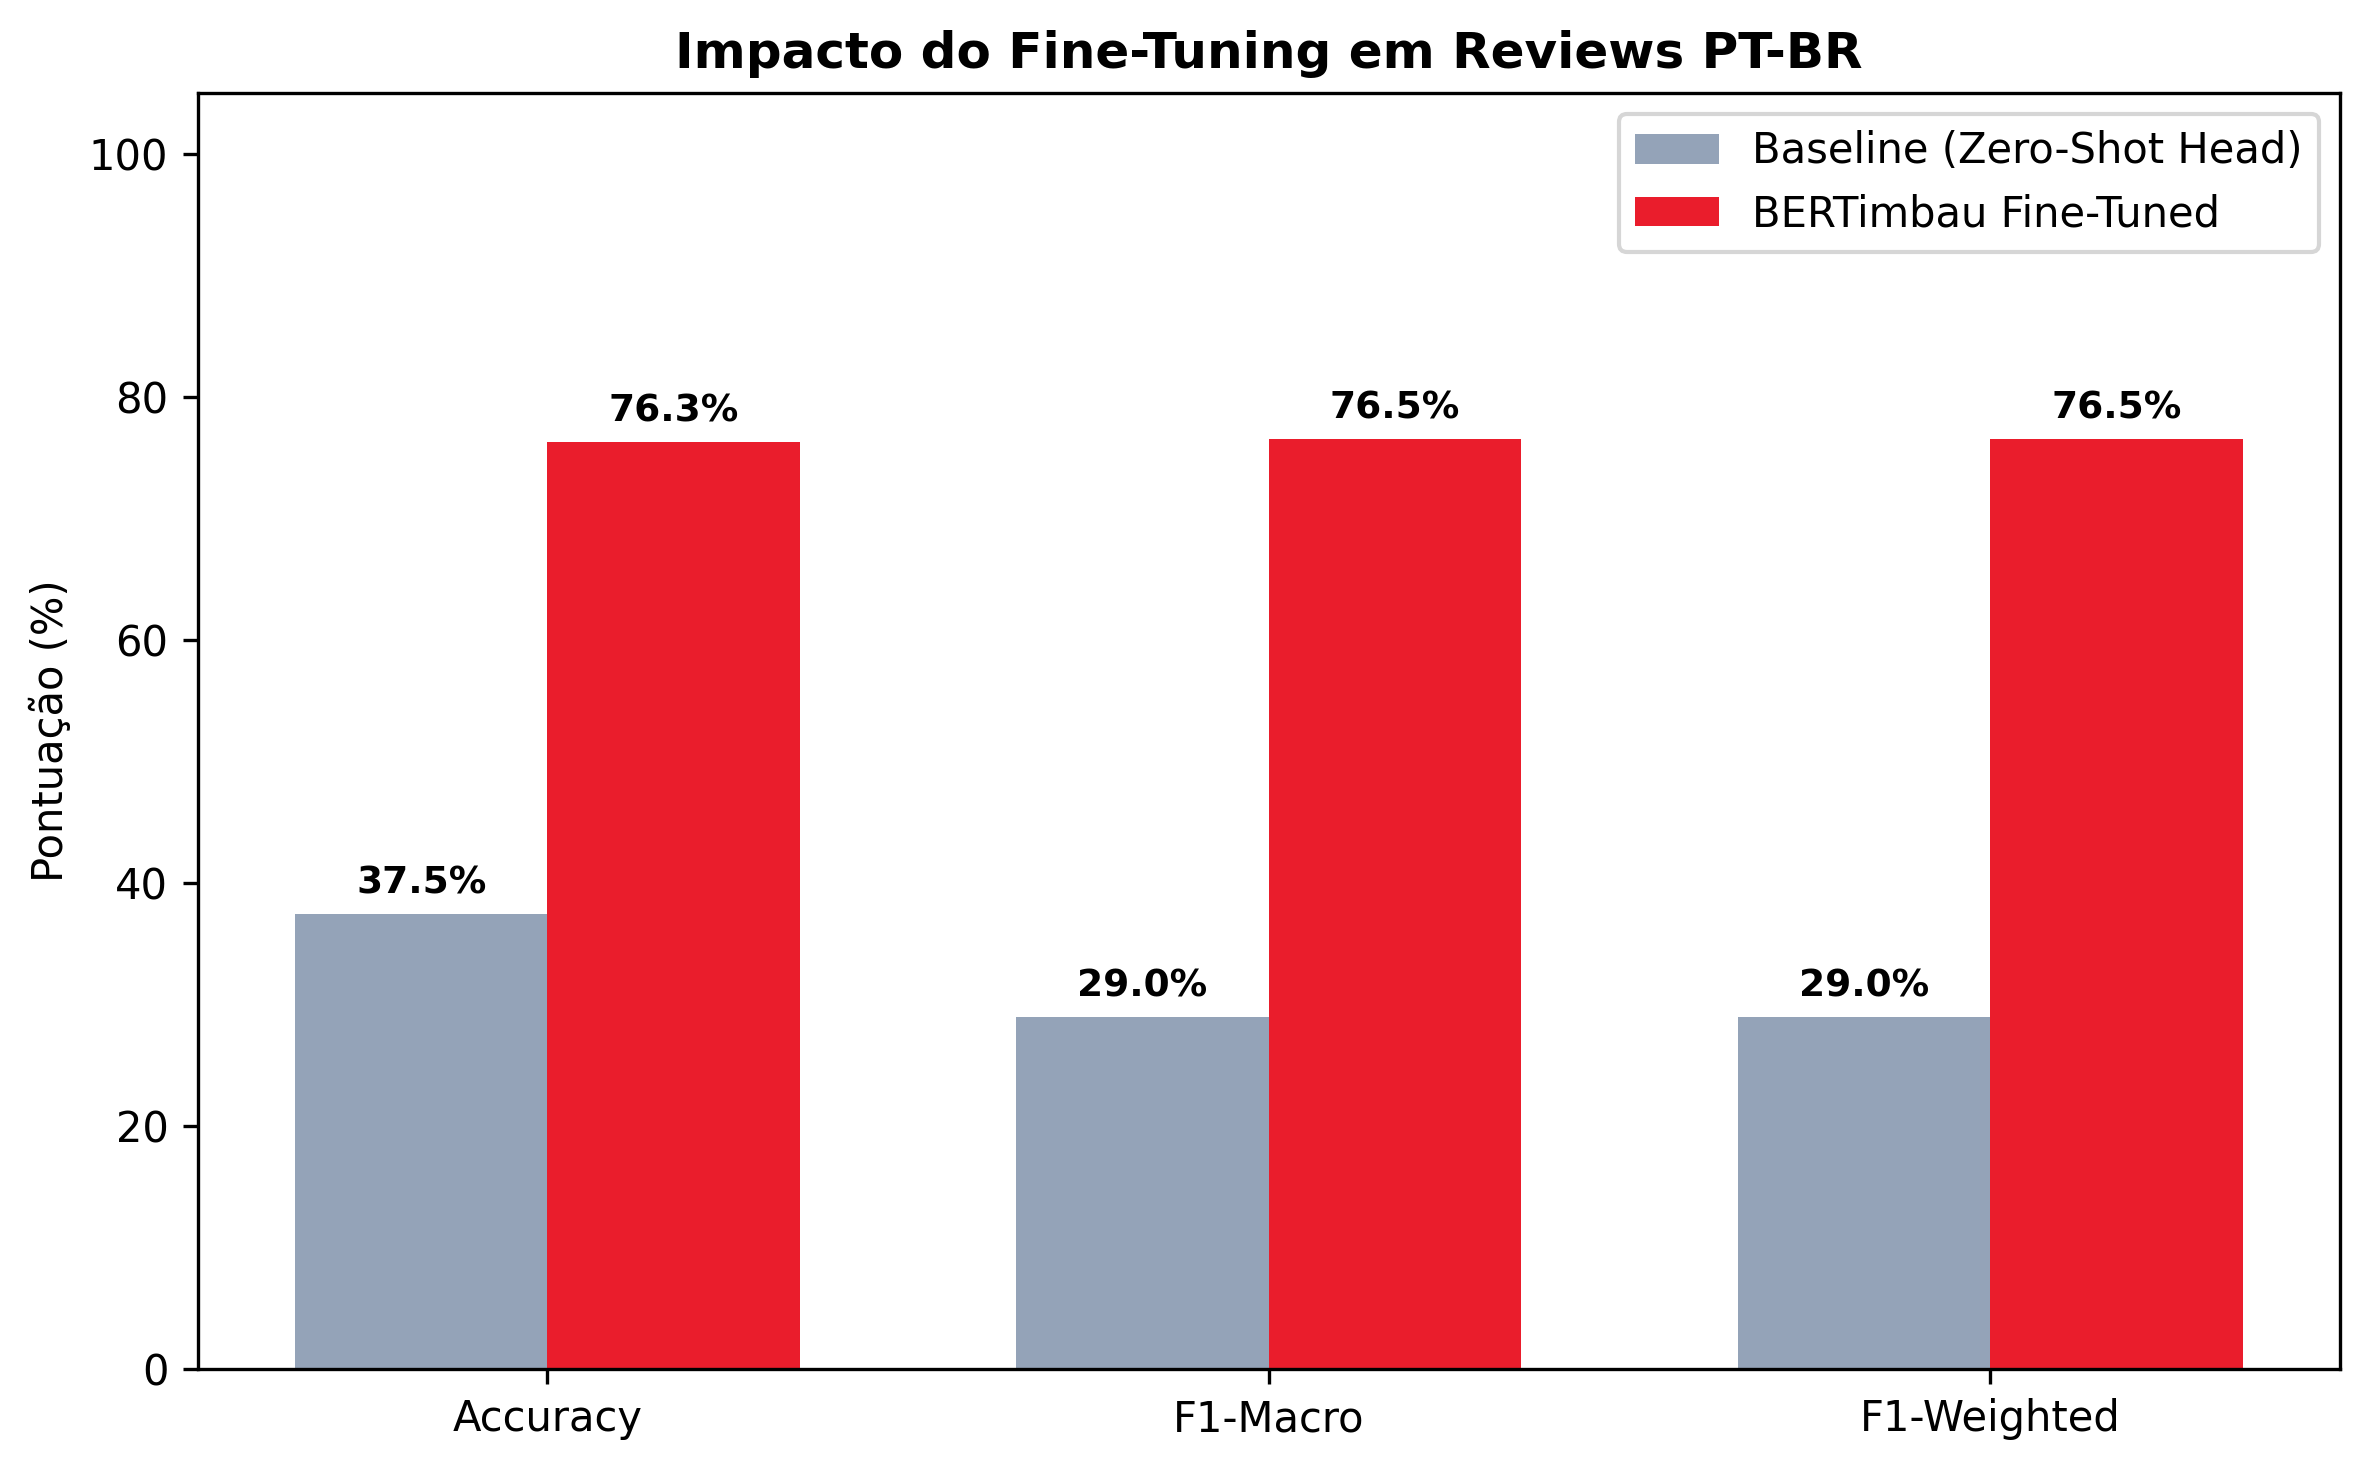

In [7]:
os.makedirs("reports", exist_ok=True)

# Avalia modelo após Fine-Tuning no conjunto de teste inédito
ft_preds, ft_acc, ft_f1_macro, ft_f1_weighted = evaluate_predictions(trainer.model, tokenized_datasets["test"])
y_true = tokenized_datasets["test"]["label"]

print("\n--- RESULTADOS PÓS FINE-TUNING (TEST SET) ---")
print(classification_report(y_true, ft_preds, target_names=["Negativo", "Neutro", "Positivo"], digits=4))

# 1. Salva Matriz de Confusão
cm = confusion_matrix(y_true, ft_preds)
plt.figure(figsize=(7, 5.5), dpi=300)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negativo", "Neutro", "Positivo"],
    yticklabels=["Negativo", "Neutro", "Positivo"]
)
plt.title("Matriz de Confusão - BERTimbau Fine-Tuned (Test Set)", fontsize=12, fontweight="bold")
plt.ylabel("Classe Real", fontsize=10)
plt.xlabel("Classe Predita", fontsize=10)
plt.tight_layout()
plt.savefig("reports/confusion_matrix.png", dpi=300)
plt.show()

# 2. Salva Gráfico Comparativo (Baseline vs Fine-Tuned)
metrics_names = ["Accuracy", "F1-Macro", "F1-Weighted"]
base_scores = [base_acc * 100, base_f1_macro * 100, base_f1_weighted * 100]
ft_scores = [ft_acc * 100, ft_f1_macro * 100, ft_f1_weighted * 100]

x = np.arange(len(metrics_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
rects1 = ax.bar(x - width/2, base_scores, width, label="Baseline (Zero-Shot Head)", color="#94a3b8")
rects2 = ax.bar(x + width/2, ft_scores, width, label="BERTimbau Fine-Tuned", color="#ea1d2c")

ax.set_ylabel("Pontuação (%)")
ax.set_title("Impacto do Fine-Tuning em Reviews PT-BR", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.set_ylim(0, 105)
ax.legend()

for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f"{height:.1f}%",
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("reports/metrics_comparison.png", dpi=300)
plt.show()

# 3. Exporta JSON de métricas
metrics_summary = {
    "baseline": {"accuracy": round(base_acc, 4), "f1_macro": round(base_f1_macro, 4), "f1_weighted": round(base_f1_weighted, 4)},
    "fine_tuned": {"accuracy": round(ft_acc, 4), "f1_macro": round(ft_f1_macro, 4), "f1_weighted": round(ft_f1_weighted, 4)}
}
with open("reports/metrics_comparison.json", "w") as f:
    json.dump(metrics_summary, f, indent=2)

In [12]:
HF_REPO_ID = "GetulioCO/bertimbau-ptbr-review-classifier"

# 1. Envia modelo e tokenizador para o Hugging Face Hub
trainer.model.push_to_hub(HF_REPO_ID)
tokenizer.push_to_hub(HF_REPO_ID)

# 2. Monta o Model Card sem blocos de crases aninhados
linhas_card = [
    "---",
    "language:",
    "- pt",
    "license: mit",
    "tags:",
    "- text-classification",
    "- sentiment-analysis",
    "- portuguese",
    "- bertimbau",
    "- ecommerce-reviews",
    "datasets:",
    "- ruanchaves/b2w-reviews01",
    "metrics:",
    "- accuracy",
    "- f1",
    "base_model: neuralmind/bert-base-portuguese-cased",
    "---",
    "",
    "# BERTimbau PT-BR Customer Review Classifier",
    "",
    "Modelo baseado em `neuralmind/bert-base-portuguese-cased` ajustado (fine-tuned) para classificacao de sentimentos em avaliacoes de clientes em portugues do Brasil (`Negativo`, `Neutro`, `Positivo`).",
    "",
    "## Metricas de Avaliacao (Conjunto de Teste)",
    "",
    "| Modelo | Accuracy | F1-Macro | F1-Weighted |",
    "| :--- | :---: | :---: | :---: |",
    f"| **Baseline (Sem Fine-Tuning)** | {base_acc:.4f} | {base_f1_macro:.4f} | {base_f1_weighted:.4f} |",
    f"| **BERTimbau Fine-Tuned** | **{ft_acc:.4f}** | **{ft_f1_macro:.4f}** | **{ft_f1_weighted:.4f}** |",
    "",
    "## Como Usar",
    "",
    "    from transformers import pipeline",
    f"    classifier = pipeline('text-classification', model='{HF_REPO_ID}')",
    "    print(classifier('O pedido chegou antes do prazo e a comida estava excelente!'))",
    "",
    "## Detalhes de Treinamento",
    "- **Dataset:** Amostra balanceada de 7.500 avaliacoes do `ruanchaves/b2w-reviews01` (2.500 por classe).",
    "- **Hiperparametros:** 3 epocas, `learning_rate=2e-5`, `batch_size=32`, `max_length=160`, precisao mista `fp16`."
]

with open("MODEL_CARD.md", "w", encoding="utf-8") as f:
    f.write("\n".join(linhas_card))

api = HfApi()
api.upload_file(
    path_or_fileobj="MODEL_CARD.md",
    path_in_repo="README.md",
    repo_id=HF_REPO_ID,
    repo_type="model"
)

print(f"Modelo publicado com sucesso em: [https://huggingface.co/](https://huggingface.co/){HF_REPO_ID}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...puk5kh4/model.safetensors:   0%|          |  557kB /  436MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Modelo publicado com sucesso em: [https://huggingface.co/](https://huggingface.co/)GetulioCO/bertimbau-ptbr-review-classifier
